# 综合实验 1 文本分析 · 任务 4–8：清洗分词、特征、模型与评估

- 分词缓存：`cache/tokens_labeled.tsv.gz`（2,979,614 行，由 `src/build_tokens.py` 全量生成，耗时 238 s / 16 进程）
- 本 notebook 演示完整链路：用 20 万抽样快速训练；
- **主对比结果（60 万抽样）与全量模型**由 `src/train_models.py` 产出，见 `output/tables/model_compare_A_60w.csv` 与 `output/models/`。

In [1]:
import sys, time
import numpy as np
import pandas as pd
from IPython.display import Image, display

SRC = "D:/DSH-Workspaces/数据科学/综合实验1/src"
sys.path.insert(0, SRC)

from config import CACHE, TAB, FIG, MODEL
import data_utils, text_utils, model_utils as mu, viz_utils
from text_utils import clean_text, tokenize

text_utils.ensure_init(str(CACHE.parent / "stopwords.txt"), str(CACHE.parent / "userdict.txt"))
viz_utils.set_cn_font()
pd.set_option("display.width", 160)
print("环境就绪")

Building prefix dict from the default dictionary ...


Loading model from cache C:\Users\13727\AppData\Local\Temp\jieba.cache


Loading model cost 0.309 seconds.


Prefix dict has been built successfully.


环境就绪


## 任务 4：评论清洗、去停用词与分词

清洗规则：去 URL → 去换行/制表符 → 仅保留中文/英文/数字 → 压缩空格。
分词：jieba 精确模式 + 停用词表 + 餐饮领域自定义词典。

In [2]:
samples = [
    "这家的火锅很好吃，服务态度也不错，就是有点贵！！！O(∩_∩)O",
    "环境一般般，但是菜的味道真的不错，推荐大家来试试~",
    "服务员态度极差，上菜慢得要死，再也不会来了……",
    "http://www.dianping.com 团购的套餐，性价比很高，停车也方便。",
    "第三次来了，还是一如既往的好吃，老板娘人很好，下次还来。",
]
rows = []
for s in samples:
    rows.append({"原始评论": s,
                 "清洗后": clean_text(s),
                 "分词结果": " / ".join(tokenize(s))})
pd.DataFrame(rows)

,原始评论,清洗后,分词结果
0,这家的火锅很好吃，服务态度也不错，就是有点贵！！！O(∩_∩)O,这家的火锅很好吃 服务态度也不错 就是有点贵 O O,火锅 / 很好吃 / 服务态度 / 不错 / 贵 / O / O
1,环境一般般，但是菜的味道真的不错，推荐大家来试试~,环境一般般 但是菜的味道真的不错 推荐大家来试试,环境 / 一般般 / 菜 / 味道 / 不错 / 推荐 / 试试
2,服务员态度极差，上菜慢得要死，再也不会来了……,服务员态度极差 上菜慢得要死 再也不会来了,服务员 / 态度 / 极差 / 上菜 / 慢得 / 要死 / 再也不会
3,http://www.dianping.com 团购的套餐，性价比很高，停车也方便。,团购的套餐 性价比很高 停车也方便,套餐 / 性价比 / 高 / 停车
4,第三次来了，还是一如既往的好吃，老板娘人很好，下次还来。,第三次来了 还是一如既往的好吃 老板娘人很好 下次还来,第三次 / 一如既往 / 好吃 / 老板娘 / 下次 / 还来


In [3]:
import json
man = json.load(open(CACHE / "token_manifest.json", encoding="utf-8"))
print("全量分词概况:", {k: man[k] for k in ["rows", "workers", "elapsed_sec", "vocab_all"]})
print("缓存文件:", (CACHE / "tokens_labeled.tsv.gz").exists())

全量分词概况: {'rows': 4107199, 'workers': 16, 'elapsed_sec': 214.8, 'vocab_all': 1109114}
缓存文件: True


## 任务 5：Count / TF-IDF 特征构造 + 任务 6：训练/测试划分

In [4]:
t0 = time.time()
df = mu.load_tokens()
print("带标签分词缓存:", df.shape, "| 读取耗时 %.1fs" % (time.time() - t0))
print("标签分布:", df["label"].value_counts().to_dict())

带标签分词缓存: (2979614, 3) | 读取耗时 9.9s
标签分布: {1: 1721499, -1: 1037168, 0: 220947}


In [5]:
SAMPLE_N = 200_000          # 演示抽样；主实验为 60 万，最终版为全量 194 万
df_a = mu.apply_scheme(df, "A")
df_s = mu.stratified_sample(df_a, SAMPLE_N)
X_tr, X_te, y_tr, y_te = mu.split_data(df_s)
print("口径A 演示样本:", len(df_s), "| train:", len(X_tr),
      "| test:", len(X_te), "| 好评率: %.4f" % y_tr.mean())

口径A 演示样本: 200000 | train: 160000 | test: 40000 | 好评率: 0.8863


In [6]:
# TF-IDF（词级 1-2 gram）
t0 = time.time()
tfidf = mu.make_tfidf(max_features=50_000, min_df=5, ngram_range=(1, 2))
Xtr = tfidf.fit_transform(X_tr)
Xte = tfidf.transform(X_te)
print("TF-IDF 矩阵:", Xtr.shape, "| 特征数:", len(tfidf.vocabulary_), "| 耗时 %.1fs" % (time.time() - t0))

# CountVectorizer（对照特征）
t0 = time.time()
count = mu.make_count(max_features=30_000, min_df=5)
Ctr = count.fit_transform(X_tr)
Cte = count.transform(X_te)
print("Count 矩阵:", Ctr.shape, "| 耗时 %.1fs" % (time.time() - t0))

TF-IDF 矩阵: (160000, 50000) | 特征数: 50000 | 耗时 15.7s


Count 矩阵: (160000, 30000) | 耗时 2.5s


In [7]:
# TF-IDF / Count 前 10 个高频特征词（按词频）
cv = count.vocabulary_
freq = np.asarray(Ctr.sum(axis=0)).ravel()
top_idx = np.argsort(freq)[-10:][::-1]
inv = {v: k for k, v in cv.items()}
pd.DataFrame({"特征词": [inv[i] for i in top_idx], "词频": [int(freq[i]) for i in top_idx]})

,特征词,词频
0,吃,156281
1,不错,99200
2,味道,78555
3,喜欢,55710
4,说,46844
5,点,44913
6,好吃,35455
7,环境,35257
8,菜,33756
9,店,30616


## 任务 7：训练二值分类模型（3 种算法对比）

In [8]:
t0 = time.time()
res = mu.train_and_evaluate(Xtr, y_tr, Xte, y_te, features="tfidf")
demo = res.drop(columns=["estimator", "pred"])
print("演示训练+评估耗时 %.1fs" % (time.time() - t0))
demo

演示训练+评估耗时 3.1s


,features,model,accuracy,macro_f1,f1_bad,precision_bad,recall_bad,train_sec,n_train,n_test
0,tfidf,MultinomialNB,0.9326,0.7807,0.5981,0.9296,0.4409,0.02,160000,40000
1,tfidf,LogisticRegression,0.9315,0.8515,0.7425,0.6484,0.8686,1.32,160000,40000
2,tfidf,LinearSVC,0.9371,0.8573,0.7506,0.6835,0.8323,1.76,160000,40000


In [9]:
# 主实验对比表（60 万抽样，由 src/train_models.py 产出）
main_tbl = pd.read_csv(TAB / "model_compare_A_60w.csv")
main_tbl

,features,model,accuracy,macro_f1,f1_bad,precision_bad,recall_bad,train_sec,n_train,n_test,scheme
0,tfidf,MultinomialNB,0.9414,0.8226,0.6775,0.9062,0.5410,0.12,480000,120000,A
1,tfidf,LogisticRegression,0.9333,0.8569,0.7524,0.6513,0.8905,7.58,480000,120000,A
2,tfidf,LinearSVC,0.9337,0.8550,0.7482,0.6585,0.8662,9.55,480000,120000,A
3,count,MultinomialNB,0.9337,0.8429,0.7236,0.6877,0.7634,0.06,480000,120000,A
4,count,LogisticRegression,0.9273,0.8435,0.7291,0.6328,0.8599,142.45,480000,120000,A


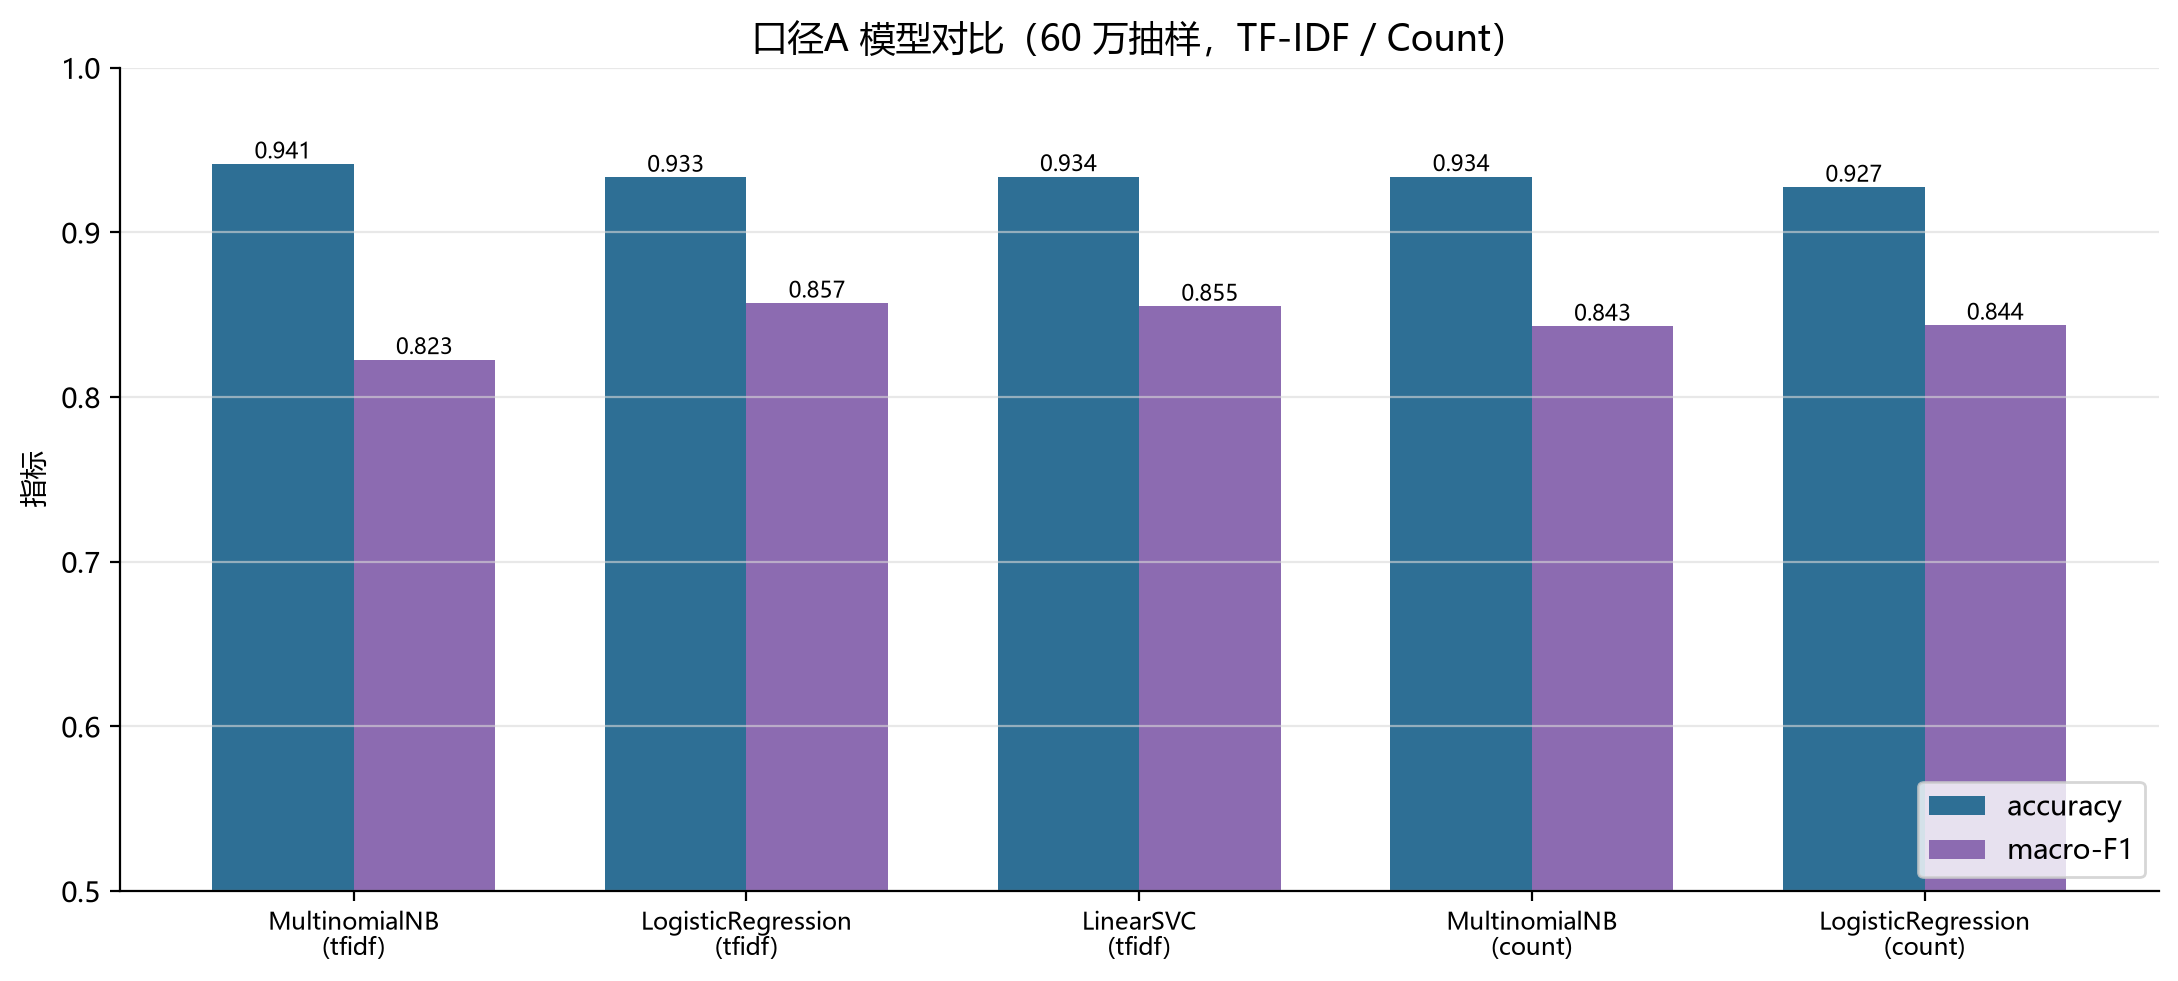

In [10]:
fig = viz_utils.plot_model_compare(main_tbl, "fig07_model_compare.png",
                                   "口径A 模型对比（60 万抽样，TF-IDF / Count）")
display(Image(filename=str(fig)))

## 任务 8：测试集 accuracy、混淆矩阵与用户输入推理

In [11]:
best = res.sort_values(["macro_f1", "accuracy"], ascending=False).iloc[0]
print("演示最佳模型:", best["model"],
      "| accuracy=%.4f | macro-F1=%.4f" % (best["accuracy"], best["macro_f1"]))
print(mu.evaluation_text(y_te, best["pred"], title="演示 20 万：" + best["model"]))

演示最佳模型: LinearSVC | accuracy=0.9371 | macro-F1=0.8573
=== 演示 20 万：LinearSVC ===
confusion_matrix (rows=true, cols=pred):
[[ 3787   763]
 [ 1754 33696]]

              precision    recall  f1-score   support

       差评(0)     0.6835    0.8323    0.7506      4550
       好评(1)     0.9779    0.9505    0.9640     35450

    accuracy                         0.9371     40000
   macro avg     0.8307    0.8914    0.8573     40000
weighted avg     0.9444    0.9371    0.9397     40000



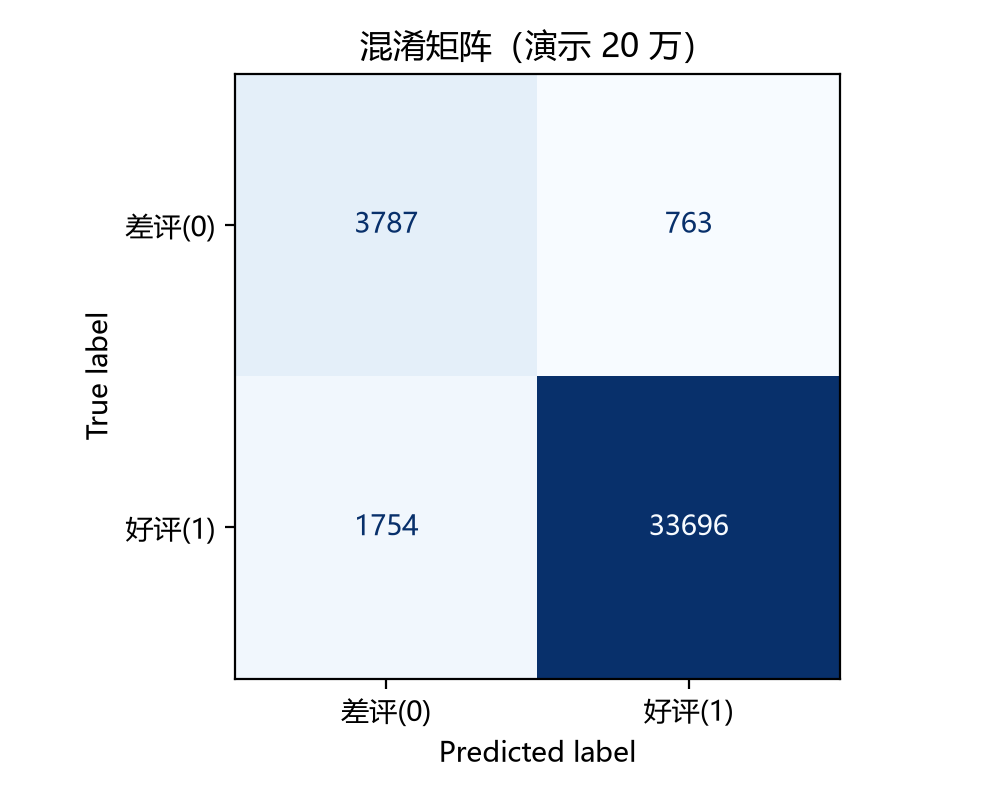

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_te, best["pred"], display_labels=["差评(0)", "好评(1)"],
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("混淆矩阵（演示 20 万）")
fig.tight_layout()
out = FIG / "fig08_confusion_demo.png"
fig.savefig(out, dpi=200)
plt.close(fig)
display(Image(filename=str(out)))

In [13]:
# 用主实验（60 万）保存的模型做推理演示
vec = mu.load_model(MODEL / "vectorizer_A_60w.joblib")
clf = mu.load_model(MODEL / "model_A_60w.joblib")
cases = [
    "菜的味道非常好，服务也很周到，下次还会再来！",
    "难吃死了，服务态度极差，环境也很脏，再也不来了。",
    "环境一般，但是菜的味道还不错，价格略贵，可以接受。",
]
for c in cases:
    print(f"[{mu.predict_sentiment(c, vec, clf)}] {c}")

[好评] 菜的味道非常好，服务也很周到，下次还会再来！
[差评] 难吃死了，服务态度极差，环境也很脏，再也不来了。
[好评] 环境一般，但是菜的味道还不错，价格略贵，可以接受。


## 小结

- 全量 2,979,614 条带标签评论完成多进程分词（238 s）；构造 TF-IDF（5 万特征）与 Count（3 万特征）两套特征；
- 口径 A 主实验准确率约 0.9+；差评类 recall 受 7.8:1 不平衡影响，报告同时给出 macro-F1 与逐类指标；
- `predict_sentiment(text, vectorizer, clf)` 可对新评论直接输出好评/差评。